<a href="https://colab.research.google.com/github/drdave-teaching/OPIM3510-BDA1/blob/main/M1_Python_Bootcamp/Week04_Dirty_Data/Project_DirtyEnergyWeather_answers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dirty Data: Weather and Energy
----------------------------------
**OPIM 3510 Python Bootcamp · Dr. Dave Wanik · University of Connecticut** (optional project)

The purpose of this notebook is to give you experience on applying the tools and methods you've learned about to real-world data. We will show how to:
* clean datasets and resample to the same temporal resolution
* make a map and color by a continuous numeric value
* create compelling visualizations and features
* selecting data based on a condition(s)
* joining datasets
* cleaning/processing text columns

Here we go!

# Import Modules
You will always have these three at the top of your script.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Download the energy data from ISO-NE

There is wonderful data all around you - here is some energy data from ISO New England.

* https://www.iso-ne.com/isoexpress/web/reports/load-and-demand

<center>

!['ISO-Logo'](https://upload.wikimedia.org/wikipedia/commons/thumb/a/a4/ISO_New_England.svg/1280px-ISO_New_England.svg.png)

**Figure:** the logo for ISO New England

![Service area](https://www.iso-ne.com/static-assets/img/ISO038-new-england-load-map3.png)

**Figure:** the service area for ISO New England

![command center](http://d279m997dpfwgl.cloudfront.net/wp/2017/05/isonewengland_control_room_v1-1000x667.jpg)

**Figure:** a view of the command center!

This website says you have to use the captcha and download the data - but you can hack it!

Look at the path from the website:

`https://www.iso-ne.com/transform/csv/hourlysystemdemand?start=20200825&end=20200829`

See the start and end time? Hack it and get it to match your dataset for any time period.

In [2]:
# I hacked the ISO-NE link (above) to get Aug 25-29, 2020 - a saved copy lives in the course GitHub repo
DATA_URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM3510-BDA1/main/data/isone_hourly_system_load_20200825_20200829.csv"

In [3]:
# you can always try to open in excel, otherwise skips rows one at a time
# or try to read using read_table() and figure out what to skip and where the header is
energy = pd.read_csv(DATA_URL, 
                     skiprows=5, # this removes the first few rows
                     skipfooter=1, # this removes the last N rows - play with it!
                     engine='python') # skipfooter needs the python engine
energy

,H,Date,HE,MWh
0,D,08/25/2020,1,14986.78
1,D,08/25/2020,2,14433.29
2,D,08/25/2020,3,14152.24
3,D,08/25/2020,4,13846.08
4,D,08/25/2020,5,13872.55
...,...,...,...,...
115,D,08/29/2020,20,16294.48
116,D,08/29/2020,21,16026.35
117,D,08/29/2020,22,15253.02
118,D,08/29/2020,23,14263.40


In [4]:
# let's explore the energy data
energy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   H       120 non-null    object 
 1   Date    120 non-null    object 
 2   HE      120 non-null    int64  
 3   MWh     120 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB


This dataset looks nice and clean. We have one column for the date and one column for the hour. We will need to bring these together.

* https://stackoverflow.com/questions/17978092/combine-date-and-time-columns-using-python-pandas

In [5]:
# let's get the hours on the scale of 0 to 23
energy['HE'] = pd.to_numeric(energy['HE'])
# now subtract one
energy['HE'] = energy['HE'] - 1
# check your work
energy 

,H,Date,HE,MWh
0,D,08/25/2020,0,14986.78
1,D,08/25/2020,1,14433.29
2,D,08/25/2020,2,14152.24
3,D,08/25/2020,3,13846.08
4,D,08/25/2020,4,13872.55
...,...,...,...,...
115,D,08/29/2020,19,16294.48
116,D,08/29/2020,20,16026.35
117,D,08/29/2020,21,15253.02
118,D,08/29/2020,22,14263.40


In [6]:
# convert to a date column
energy['Date'] = pd.to_datetime(energy['Date'])
energy

,H,Date,HE,MWh
0,D,2020-08-25,0,14986.78
1,D,2020-08-25,1,14433.29
2,D,2020-08-25,2,14152.24
3,D,2020-08-25,3,13846.08
4,D,2020-08-25,4,13872.55
...,...,...,...,...
115,D,2020-08-29,19,16294.48
116,D,2020-08-29,20,16026.35
117,D,2020-08-29,21,15253.02
118,D,2020-08-29,22,14263.40


Make a new datetime column
* https://stackoverflow.com/questions/52281633/pandas-convert-the-number-of-the-day-and-the-hour

In [7]:
# now push them together!
energy['Date'] = energy['Date'] + pd.to_timedelta(energy['HE'], unit='h')
energy

,H,Date,HE,MWh
0,D,2020-08-25 00:00:00,0,14986.78
1,D,2020-08-25 01:00:00,1,14433.29
2,D,2020-08-25 02:00:00,2,14152.24
3,D,2020-08-25 03:00:00,3,13846.08
4,D,2020-08-25 04:00:00,4,13872.55
...,...,...,...,...
115,D,2020-08-29 19:00:00,19,16294.48
116,D,2020-08-29 20:00:00,20,16026.35
117,D,2020-08-29 21:00:00,21,15253.02
118,D,2020-08-29 22:00:00,22,14263.40


It's often useful to make the datetime column the index. You can also make new columns for month, day, year and more if you wanted to!

In [8]:
energy.set_index(energy['Date'], inplace=True)
# check your work!
energy

,H,Date,HE,MWh
Date,,,,
2020-08-25 00:00:00,D,2020-08-25 00:00:00,0,14986.78
2020-08-25 01:00:00,D,2020-08-25 01:00:00,1,14433.29
2020-08-25 02:00:00,D,2020-08-25 02:00:00,2,14152.24
2020-08-25 03:00:00,D,2020-08-25 03:00:00,3,13846.08
2020-08-25 04:00:00,D,2020-08-25 04:00:00,4,13872.55
...,...,...,...,...
2020-08-29 19:00:00,D,2020-08-29 19:00:00,19,16294.48
2020-08-29 20:00:00,D,2020-08-29 20:00:00,20,16026.35
2020-08-29 21:00:00,D,2020-08-29 21:00:00,21,15253.02


Now you can make a nice plot of the energy demand. 

Always be conscious of what time zone your data comes from - we will skip this for now, but in the real world, you may need to tinker with this.

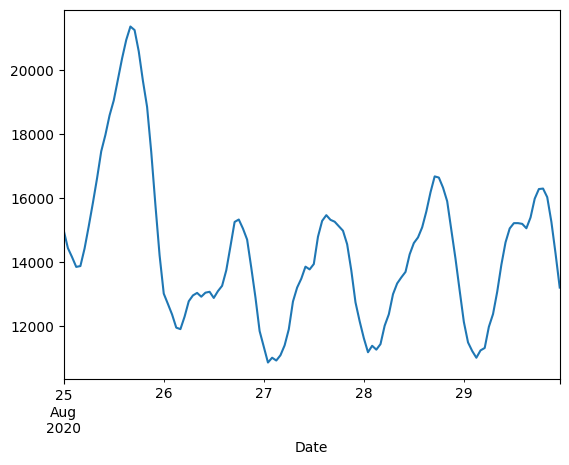

In [9]:
# here is a plot of energy demand!
energy['MWh'].plot()
plt.show()

Later on, we can join this with temperature data and explore it.

On your own - can you make this plot with better axis titles/labels?

# Download weather data to the local runtime

Feeling slick? Make a new variable for the dates so that you don't need to tinker/dig through your script to update the dates.

In [10]:
"""
Example script that scrapes data from the IEM ASOS download service
"""
from __future__ import print_function
import json
import time
import datetime

# Python 2 and 3: alternative 4
try:
    from urllib.request import urlopen
except ImportError:
    from urllib2 import urlopen

# Number of attempts to download data
MAX_ATTEMPTS = 6
# HTTPS here can be problematic for installs that don't have Lets Encrypt CA
SERVICE = "http://mesonet.agron.iastate.edu/cgi-bin/request/asos.py?"


def download_data(uri):
    """Fetch the data from the IEM
    The IEM download service has some protections in place to keep the number
    of inbound requests in check.  This function implements an exponential
    backoff to keep individual downloads from erroring.
    Args:
      uri (string): URL to fetch
    Returns:
      string data
    """
    attempt = 0
    while attempt < MAX_ATTEMPTS:
        try:
            data = urlopen(uri, timeout=300).read().decode("utf-8")
            if data is not None and not data.startswith("ERROR"):
                return data
        except Exception as exp:
            print("download_data(%s) failed with %s" % (uri, exp))
            time.sleep(5)
        attempt += 1

    print("Exhausted attempts to download, returning empty data")
    return ""


def get_stations_from_filelist(filename):
    """Build a listing of stations from a simple file listing the stations.
    The file should simply have one station per line.
    """
    stations = []
    for line in open(filename):
        stations.append(line.strip())
    return stations


def get_stations_from_networks():
    """Build a station list by using a bunch of IEM networks."""
    stations = []
    # states = """AK AL AR AZ CA CO CT DE FL GA HI IA ID IL IN KS KY LA MA MD ME
    #  MI MN MO MS MT NC ND NE NH NJ NM NV NY OH OK OR PA RI SC SD TN TX UT VA VT
    #  WA WI WV WY"""
    states = 'CT'
    # IEM quirk to have Iowa AWOS sites in its own labeled network
    networks = ["AWOS"]
    for state in states.split():
        networks.append("%s_ASOS" % (state,))

    for network in networks:
        # Get metadata
        uri = (
            "https://mesonet.agron.iastate.edu/geojson/network/%s.geojson"
        ) % (network,)
        data = urlopen(uri)
        jdict = json.load(data)
        for site in jdict["features"]:
            stations.append(site["properties"]["sid"])
    return stations


def download_alldata():
    """An alternative method that fetches all available data.
    Service supports up to 24 hours worth of data at a time."""
    # timestamps in UTC to request data for
    startts = datetime.datetime(2020, 8, 25)
    endts = datetime.datetime(2020, 8, 29)
    interval = datetime.timedelta(hours=24)

    service = SERVICE + "data=all&tz=Etc/UTC&format=comma&latlon=yes&"

    now = startts
    while now < endts:
        thisurl = service
        thisurl += now.strftime("year1=%Y&month1=%m&day1=%d&")
        thisurl += (now + interval).strftime("year2=%Y&month2=%m&day2=%d&")
        print("Downloading: %s" % (now,))
        data = download_data(thisurl)
        outfn = "%s.txt" % (now.strftime("%Y%m%d"),)
        with open(outfn, "w") as fh:
            fh.write(data)
        now += interval


def main():
    """Our main method"""
    # timestamps in UTC to request data for
    startts = datetime.datetime(2020, 8, 25)
    endts = datetime.datetime(2020, 8, 29)

    service = SERVICE + "data=all&tz=Etc/UTC&format=comma&latlon=yes&"

    service += startts.strftime("year1=%Y&month1=%m&day1=%d&")
    service += endts.strftime("year2=%Y&month2=%m&day2=%d&")

    # Two examples of how to specify a list of stations
    stations = get_stations_from_networks()
    # stations = get_stations_from_filelist("mystations.txt")
    for station in stations:
        uri = "%s&station=%s" % (service, station)
        print("Downloading: %s" % (station,))
        data = download_data(uri)
        outfn = "%s_%s_%s.txt" % (
            station,
            startts.strftime("%Y%m%d%H%M"),
            endts.strftime("%Y%m%d%H%M"),
        )
        out = open(outfn, "w")
        out.write(data)
        out.close()


if __name__ == "__main__":
    download_alldata()
    # main()

Downloading: 2020-08-25 00:00:00


Downloading: 2020-08-26 00:00:00


Downloading: 2020-08-27 00:00:00


Downloading: 2020-08-28 00:00:00


Look left! All of the data you need is there. 

# Open the data!

In [11]:
import pandas as pd
df = pd.read_table('20200825.txt')
df

,#DEBUG: Format Typ -> comma
0,#DEBUG: Time Period -> 2020-08-25 00:00:00+0...
1,#DEBUG: Time Zone -> Etc/UTC
2,#DEBUG: Data Contact -> daryl herzmann akrhe...
3,#DEBUG: Entries Found -> -1
4,"station,valid,lon,lat,tmpf,dwpf,relh,drct,sknt..."
...,...
484212,"MTPP,2020-08-25 23:59,-72.2925,18.5800,82.40,7..."
484213,"MLF,2020-08-25 23:59,-113.0125,38.4266,96.00,3..."
484214,"MUCF,2020-08-25 23:59,-80.4142,22.1500,77.00,7..."
484215,"YPCC,2020-08-25 23:59,96.8344,-12.1892,78.80,7..."


Yuck! Looks like it has some nasty junk at the top. We can try to skip lines and read again.

In [12]:
# you will need to find arguments in read_table() that can help you

In [13]:
df = pd.read_table('20200825.txt', skiprows=5, sep=',')
df

,station,valid,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,...,wxcodes,ice_accretion_1hr,ice_accretion_3hr,ice_accretion_6hr,peak_wind_gust,peak_wind_drct,peak_wind_time,feel,metar,snowdepth
0,AWO,2020-08-25 00:00,-122.1590,48.1608,M,M,M,310.00,10.00,M,...,M,M,M,M,M,M,M,M,KAWO 250000Z AUTO 31010KT 10SM CLR 23/10 A2996...,M
1,BDR,2020-08-25 00:00,-73.1289,41.1583,M,M,M,180.00,8.00,M,...,M,M,M,M,M,M,M,M,KBDR 250000Z AUTO 18008KT 10SM CLR 27/23 A2989...,M
2,AQW,2020-08-25 00:00,-73.1702,42.6962,M,M,M,130.00,8.00,M,...,M,M,M,M,M,M,M,M,KAQW 250000Z AUTO 13008KT 10SM FEW085 26/16 A2...,M
3,ANB,2020-08-25 00:00,-85.8479,33.5904,M,M,M,50.00,5.00,M,...,M,M,M,M,M,M,M,M,KANB 250000Z AUTO 05005KT 10SM FEW110 28/24 A3...,M
4,BFI,2020-08-25 00:00,-122.3000,47.5300,M,M,M,300.00,7.00,M,...,M,M,M,M,M,M,M,M,KBFI 250000Z AUTO 30007KT 10SM CLR 24/07 A2995...,M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
484207,MTPP,2020-08-25 23:59,-72.2925,18.5800,82.40,73.40,74.28,0.00,0.00,0.00,...,NaN,M,M,M,M,M,M,88.26,MTPP 252359Z AUTO 00000KT 9000 ////// 28/23 Q1...,M
484208,MLF,2020-08-25 23:59,-113.0125,38.4266,96.00,39.00,13.90,200.00,17.00,0.00,...,M,M,M,M,M,M,M,91.48,KMLF 252359Z 20017G25KT 10SM CLR 36/04 A2996 R...,M
484209,MUCF,2020-08-25 23:59,-80.4142,22.1500,77.00,73.40,88.67,80.00,3.00,0.00,...,M,M,M,M,M,M,M,77.00,MUCF 252359Z AUTO 08003KT 25/23 Q1013,M
484210,YPCC,2020-08-25 23:59,96.8344,-12.1892,78.80,73.40,83.55,110.00,15.00,0.00,...,NaN,M,M,M,M,M,M,78.80,YPCC 252359Z AUTO 11015G27KT 9999 // SCT024 SC...,M


## Reading/appending multiple files
Working with each of the individual files can be OK sometimes - other times it's good to merge and read all three files. 

Let's open and append the three files.

See if you can hack this example for TEXT FILES (not .csv). Do you remember how to copy path from a file?

In [14]:
import glob
# the weather files were saved to the current folder (the Files panel in Colab)
all_files = glob.glob("*.txt")
all_files

['20200825.txt', '20200826.txt', '20200827.txt', '20200828.txt']

In [15]:
import pandas as pd
import glob

all_files = glob.glob("*.txt")

li = []

for filename in all_files:
    df = pd.read_table(filename, index_col=None, skiprows=5, sep=',')
    li.append(df)

df = pd.concat(li, axis=0, ignore_index=True)

Now let's check our work and inspect the data types (dtypes).

In [16]:
df

,station,valid,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,...,wxcodes,ice_accretion_1hr,ice_accretion_3hr,ice_accretion_6hr,peak_wind_gust,peak_wind_drct,peak_wind_time,feel,metar,snowdepth
0,AWO,2020-08-25 00:00,-122.1590,48.1608,M,M,M,310.00,10.00,M,...,M,M,M,M,M,M,M,M,KAWO 250000Z AUTO 31010KT 10SM CLR 23/10 A2996...,M
1,BDR,2020-08-25 00:00,-73.1289,41.1583,M,M,M,180.00,8.00,M,...,M,M,M,M,M,M,M,M,KBDR 250000Z AUTO 18008KT 10SM CLR 27/23 A2989...,M
2,AQW,2020-08-25 00:00,-73.1702,42.6962,M,M,M,130.00,8.00,M,...,M,M,M,M,M,M,M,M,KAQW 250000Z AUTO 13008KT 10SM FEW085 26/16 A2...,M
3,ANB,2020-08-25 00:00,-85.8479,33.5904,M,M,M,50.00,5.00,M,...,M,M,M,M,M,M,M,M,KANB 250000Z AUTO 05005KT 10SM FEW110 28/24 A3...,M
4,BFI,2020-08-25 00:00,-122.3000,47.5300,M,M,M,300.00,7.00,M,...,M,M,M,M,M,M,M,M,KBFI 250000Z AUTO 30007KT 10SM CLR 24/07 A2995...,M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1937095,SCH,2020-08-28 23:59,-73.9300,42.8500,68.00,59.00,72.92,0.00,0.00,0.00,...,M,M,M,M,M,M,M,68.00,KSCH 282359Z 00000KT 10SM CLR 20/15 A2981,M
1937096,RODN,2020-08-28 23:59,127.7676,26.3556,86.40,79.70,80.52,90.00,12.00,0.00,...,M,M,M,M,M,M,M,101.32,RODN 282359Z 09012KT 10SM FEW016 30/27 A2973 R...,M
1937097,EHKD,2020-08-28 23:59,4.7811,52.9269,57.20,55.40,93.69,210.00,9.00,0.00,...,SHRA,M,M,M,M,M,M,57.20,EHKD 282359Z AUTO 21009KT 170V250 4400 SHRA FE...,M
1937098,LAR,2020-08-28 23:59,-105.6750,41.3121,67.00,38.00,34.35,M,M,0.00,...,BLSA,M,M,M,M,M,M,66.90,KLAR 282359Z AUTO BLSA CLR 19/03 RMK AO2 T0194...,M


Wow! That is a lot of data. 

## value_counts, nunique and unique
Let's see how many airports there are.

In [17]:
df['station'].nunique() # 5k different airports!

5535

In [18]:
df['station'].unique() # the individual names of the stations
                        # too big to print

array(['AWO', 'BDR', 'AQW', ..., 'SBPG', 'FME', 'DLP'], dtype=object)

In [19]:
df['station'].value_counts() # number of observations per station

station
LAR     1620
SDM     1374
MCB     1354
PIB     1343
BTR     1335
        ... 
SPJJ       1
SLMG       1
SBJE       1
OPRN       1
FME        1
Name: count, Length: 5535, dtype: int64

Looks like some stations have a lot of data, while others have just ONE observation. We can clean this up and select those that have more than X observations. A histogram and summary statistics can help here. 

## summary statistics

In [20]:
df['station'].value_counts().describe()

count    5535.000000
mean      349.972900
std       418.330759
min         1.000000
25%        96.000000
50%       191.000000
75%       288.000000
max      1620.000000
Name: count, dtype: float64

On average, it looks like the average station has around 100 observations - this makes sense for three days of data.

Sometimes it's nice to view these data as a histogram - different patterns can emerge. Play with the `bins` argument to get some more flexibility.

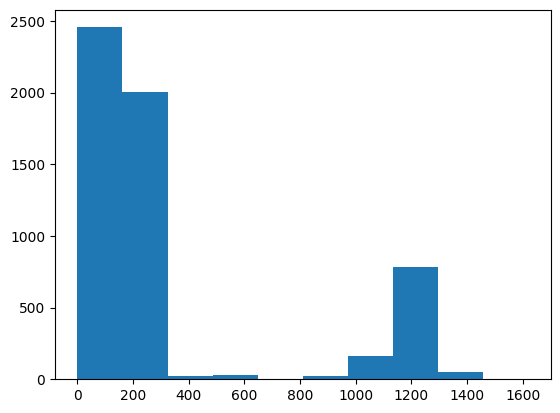

In [21]:
plt.hist(df['station'].value_counts())
plt.show()

Aha! We see quite a few outliers here... some stations have HUNDREDS of records while most seem to be between 0 and 250. A boxplot could be a nice way of summarizing the middle 50% of the data. 

## Boxplot


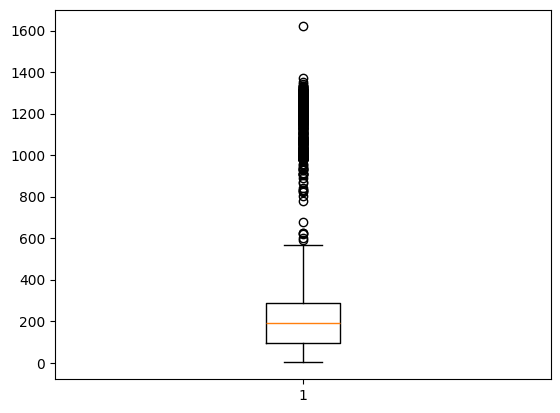

In [22]:
plt.boxplot(df['station'].value_counts())
plt.show()

If you wanted to, you could customize the Y axis so that it was easier to read (yes, there are outliers - but we might be more interested in the IQR and whiskers.

BTW - why don't you check the documentation and see what the whiskers mean... are they +/- 1.5*IQR or something different?

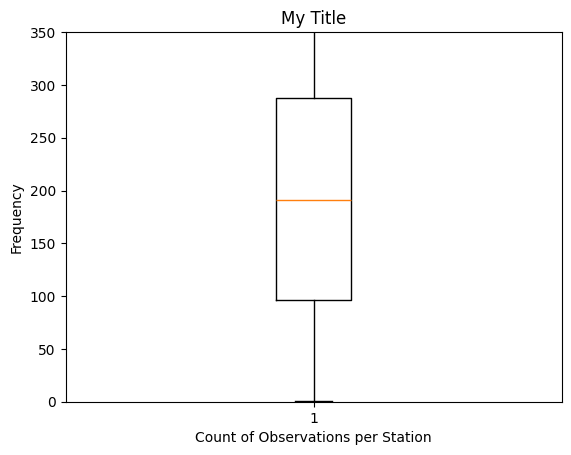

In [23]:
plt.boxplot(df['station'].value_counts())
plt.ylim([0,350])
plt.xlabel('Count of Observations per Station')
plt.ylabel('Frequency')
plt.title('My Title')
plt.show()

## kde
Which also look A LOT like kernel density plots!

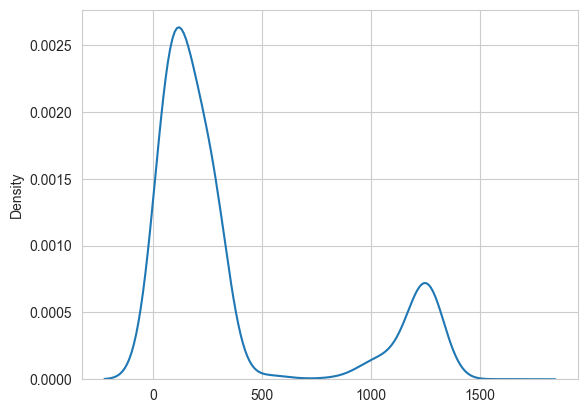

In [24]:
import seaborn as sns

sns.set_style('whitegrid')
sns.kdeplot(np.array(df['station'].value_counts()))
plt.show()

# Correlation
It's interesting to look at the correlation among variables.

In [25]:
df.corr(numeric_only=True) # only works for numeric data - see how few columns show up? we need to clean up our data types!

,lon,lat
lon,1.000000,-0.348249
lat,-0.348249,1.000000


Whenever you have latitiude and longitude in your dataset, try to explore it! Here are all of the points - should form a map of the World.

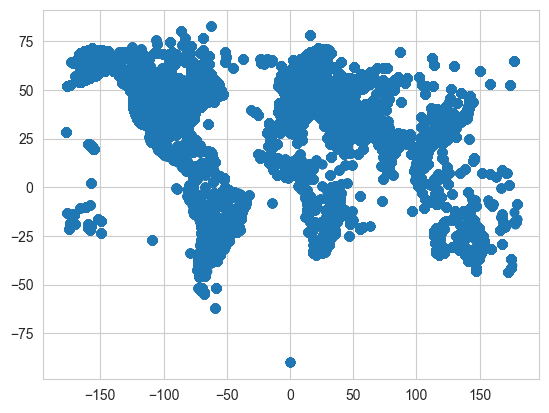

In [26]:
plt.scatter(x=df['lon'], y=df['lat'])
plt.show()

AMAZING!!! Later on when we clean up our data types, we will be able to look at temperatures all around the World (or all across New England, whatever we want to do.)

# Data Types (using `df.info()`) and the hunt for missing values

In [27]:
# uh oh! we have A LOT of dirty data... gotta clean it up!
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1937100 entries, 0 to 1937099
Data columns (total 32 columns):
 #   Column             Dtype  
---  ------             -----  
 0   station            object 
 1   valid              object 
 2   lon                float64
 3   lat                float64
 4   tmpf               object 
 5   dwpf               object 
 6   relh               object 
 7   drct               object 
 8   sknt               object 
 9   p01i               object 
 10  alti               object 
 11  mslp               object 
 12  vsby               object 
 13  gust               object 
 14  skyc1              object 
 15  skyc2              object 
 16  skyc3              object 
 17  skyc4              object 
 18  skyl1              object 
 19  skyl2              object 
 20  skyl3              object 
 21  skyl4              object 
 22  wxcodes            object 
 23  ice_accretion_1hr  object 
 24  ice_accretion_3hr  object 
 25  ice_accretion_6hr 

As you may now, missing data can be identified with 'M' or '999' or 'NA' or 'NaN' or a whole mess of other garbage. When a dataset is this big, you need to be clever with how you identify missing values.

In [28]:
df['tmpf'].unique() # do you see anything that catches your eye?
                    # I spy the letter 'M' which has forced all the other
                    # data to take on a string (object) data type...

array(['M', '82.40', '89.60', '75.20', '93.20', '77.00', '80.60', '86.00',
       '51.00', '68.40', '61.00', '59.00', '78.80', '72.30', '57.70',
       '66.70', '61.50', '58.00', '65.00', '70.00', '79.20', '67.00',
       '87.60', '62.00', '77.40', '82.00', '63.70', '67.60', '59.40',
       '80.80', '86.40', '70.70', '67.30', '53.40', '37.00', '67.50',
       '73.00', '82.80', '66.00', '57.00', '53.60', '73.20', '89.20',
       '62.60', '83.70', '93.40', '78.00', '53.20', '69.00', '61.70',
       '59.20', '66.60', '69.30', '69.80', '39.20', '64.60', '71.20',
       '71.40', '83.30', '73.40', '86.70', '81.70', '88.30', '71.00',
       '58.60', '88.50', '60.80', '75.40', '88.00', '51.40', '55.60',
       '83.00', '51.60', '68.50', '70.30', '55.00', '64.40', '67.80',
       '33.80', '71.80', '50.00', '91.00', '59.70', '89.40', '90.70',
       '64.00', '56.70', '56.50', '85.60', '68.70', '84.70', '41.00',
       '83.50', '76.60', '78.40', '63.50', '57.60', '56.30', '77.20',
       '66.40',

If missing values are common, you also might be able to investigate with `value_counts`

In [29]:
df['tmpf'].value_counts() # but it doesn't work all the time

tmpf
M         1128479
77.00       34337
73.40       29254
78.80       28250
75.20       27826
           ...   
8.60            1
-88.60          1
27.50           1
27.00           1
27.10           1
Name: count, Length: 464, dtype: int64

Now, you have a choice when there is a constant in the dataset - you get replace all 'M' with NaN or 0 (dangerous! there are better ways.) I find the best way is to convert the numeric columns all at once and COERCE the errors.

What does COERCE do? It tries to force the values to take a numeric type. This can save a lot of replacement text.

## replacing the 'M' in the 'tmpf' column

For completeness, let's show how to replace some missing values one at a time in just one column.

When searching for an answer, you might find related questions that can help you solve the problem.
* https://stackoverflow.com/questions/38516481/trying-to-remove-commas-and-dollars-signs-with-pandas-in-python/46430853

In [30]:
df['tmpf'] = df['tmpf'].str.replace('M', '') # we replace it with nothing...
df['tmpf'].unique() # see how it's now ''? 

array(['', '82.40', '89.60', '75.20', '93.20', '77.00', '80.60', '86.00',
       '51.00', '68.40', '61.00', '59.00', '78.80', '72.30', '57.70',
       '66.70', '61.50', '58.00', '65.00', '70.00', '79.20', '67.00',
       '87.60', '62.00', '77.40', '82.00', '63.70', '67.60', '59.40',
       '80.80', '86.40', '70.70', '67.30', '53.40', '37.00', '67.50',
       '73.00', '82.80', '66.00', '57.00', '53.60', '73.20', '89.20',
       '62.60', '83.70', '93.40', '78.00', '53.20', '69.00', '61.70',
       '59.20', '66.60', '69.30', '69.80', '39.20', '64.60', '71.20',
       '71.40', '83.30', '73.40', '86.70', '81.70', '88.30', '71.00',
       '58.60', '88.50', '60.80', '75.40', '88.00', '51.40', '55.60',
       '83.00', '51.60', '68.50', '70.30', '55.00', '64.40', '67.80',
       '33.80', '71.80', '50.00', '91.00', '59.70', '89.40', '90.70',
       '64.00', '56.70', '56.50', '85.60', '68.70', '84.70', '41.00',
       '83.50', '76.60', '78.40', '63.50', '57.60', '56.30', '77.20',
       '66.40', 

Now you can coerce this column to a numeric data type.

In [31]:
print('Before:', df['tmpf'].dtype)
df['tmpf'] = pd.to_numeric(df['tmpf'], errors='coerce')
print('After:', df['tmpf'].dtype) # :)

Before: object


After: float64


LEt's count the missing values in this column now that things have been coerced.

In [32]:
df['tmpf'].isna().sum() # this is the count of missing values

np.int64(1128479)

You could also find this using df.info()...

In [33]:
df.info() # see how the non-null count is less? 
          # and how the data type is correct?

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1937100 entries, 0 to 1937099
Data columns (total 32 columns):
 #   Column             Dtype  
---  ------             -----  
 0   station            object 
 1   valid              object 
 2   lon                float64
 3   lat                float64
 4   tmpf               float64
 5   dwpf               object 
 6   relh               object 
 7   drct               object 
 8   sknt               object 
 9   p01i               object 
 10  alti               object 
 11  mslp               object 
 12  vsby               object 
 13  gust               object 
 14  skyc1              object 
 15  skyc2              object 
 16  skyc3              object 
 17  skyc4              object 
 18  skyl1              object 
 19  skyl2              object 
 20  skyl3              object 
 21  skyl4              object 
 22  wxcodes            object 
 23  ice_accretion_1hr  object 
 24  ice_accretion_3hr  object 
 25  ice_accretion_6hr 

# Data Dictionary
When possible, it's always good to look at the data dictionary - let's find out which columns should be numeric and convert them.
* https://mesonet.agron.iastate.edu/request/download.phtml

Which columns are numeric and which are objects/text?

## Converting multiple columns to numeric

StackOverflow is filled with solid gold - your question has likely already been solved :)

* https://stackoverflow.com/questions/36814100/pandas-to-numeric-for-multiple-columns

Hack it and go! See the power of 'apply' for repeating certain operations? No need for a for loop. Always strive to avoid using a for loop whenever possible.

In [34]:
# i think we should convert tmpf through gust
cols = df.columns[4:14]
print('original:', df.columns)
print('simplified:', cols) # it seems most times start is included, but end is not (so add +1 to range)

original: Index(['station', 'valid', 'lon', 'lat', 'tmpf', 'dwpf', 'relh', 'drct',
       'sknt', 'p01i', 'alti', 'mslp', 'vsby', 'gust', 'skyc1', 'skyc2',
       'skyc3', 'skyc4', 'skyl1', 'skyl2', 'skyl3', 'skyl4', 'wxcodes',
       'ice_accretion_1hr', 'ice_accretion_3hr', 'ice_accretion_6hr',
       'peak_wind_gust', 'peak_wind_drct', 'peak_wind_time', 'feel', 'metar',
       'snowdepth'],
      dtype='object')
simplified: Index(['tmpf', 'dwpf', 'relh', 'drct', 'sknt', 'p01i', 'alti', 'mslp', 'vsby',
       'gust'],
      dtype='object')


In [35]:
# now let's make our numeric columns the correct data type
df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')
# and check your work
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1937100 entries, 0 to 1937099
Data columns (total 32 columns):
 #   Column             Dtype  
---  ------             -----  
 0   station            object 
 1   valid              object 
 2   lon                float64
 3   lat                float64
 4   tmpf               float64
 5   dwpf               float64
 6   relh               float64
 7   drct               float64
 8   sknt               float64
 9   p01i               float64
 10  alti               float64
 11  mslp               float64
 12  vsby               float64
 13  gust               float64
 14  skyc1              object 
 15  skyc2              object 
 16  skyc3              object 
 17  skyc4              object 
 18  skyl1              object 
 19  skyl2              object 
 20  skyl3              object 
 21  skyl4              object 
 22  wxcodes            object 
 23  ice_accretion_1hr  object 
 24  ice_accretion_3hr  object 
 25  ice_accretion_6hr 

# [optional] Make a map
Now that you have wonderful data - go do something with it! You already saw that your data had a geospatial component - why not try making a map of max and min temperature across time?

We can try many different approaches, but to start, why not just make a scatterplot like we did before and color it by some z value.

In [36]:
# first, let's simplify the dataframe
# it's true that we haven't resampled or cleaned the dataframe yet
# this is just for a quick demonstation
# lat and lon don't vary per location so taking max/min is fine
tmp = df[['station', 'lat', 'lon', 'tmpf']]
tmp

,station,lat,lon,tmpf
0,AWO,48.1608,-122.1590,NaN
1,BDR,41.1583,-73.1289,NaN
2,AQW,42.6962,-73.1702,NaN
3,ANB,33.5904,-85.8479,NaN
4,BFI,47.5300,-122.3000,NaN
...,...,...,...,...
1937095,SCH,42.8500,-73.9300,68.0
1937096,RODN,26.3556,127.7676,86.4
1937097,EHKD,52.9269,4.7811,57.2
1937098,LAR,41.3121,-105.6750,67.0


In [37]:
# for simplicity, less just drop any missing values
tmp = tmp.dropna()
tmp.isna().sum() # good to go!

station    0
lat        0
lon        0
tmpf       0
dtype: int64

In [38]:
# now calculate the max per station using a groupby
tmp2 = tmp.groupby(tmp['station']).max()
tmp2

,lat,lon,tmpf
station,,,
00U,45.7444,-107.6604,95.0
04V,38.1000,-106.1700,86.0
04W,46.0229,-92.8952,82.4
05U,39.6042,-116.0051,95.0
06C,41.9913,-88.1050,92.3
...,...,...,...
ZYCC,43.9900,125.6800,80.6
ZYHB,46.0200,126.5800,82.4
ZYTL,38.9000,121.6333,82.4


Now make a scatterplot of lat vs. lon and color by tmpf (max temperature!) See how your data comes to life?
* https://seaborn.pydata.org/generated/seaborn.scatterplot.html

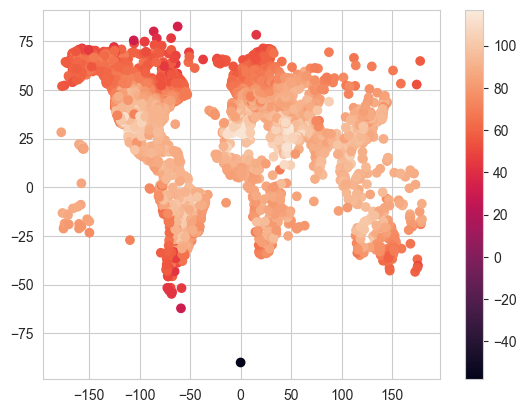

In [39]:
# sometimes you need a colorbar instead of a legend
example = plt.scatter(x=tmp2['lon'], y=tmp2['lat'], c = tmp2['tmpf'])
plt.colorbar(example)
plt.show() # you can try to add a legend!

**On your own:** Why not redo the code and see where the coldest temperatures are? Add labels and a title.

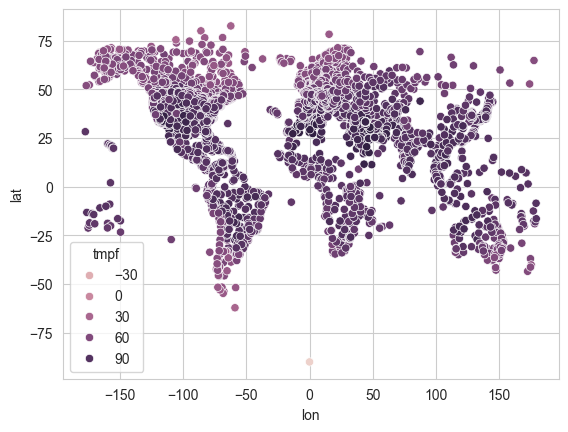

In [40]:
# a basic scatterplot
sns.scatterplot(x=tmp2['lon'], y=tmp2['lat'], hue = tmp2['tmpf'])
plt.show() 

Try to zoom in on Connecticut. 

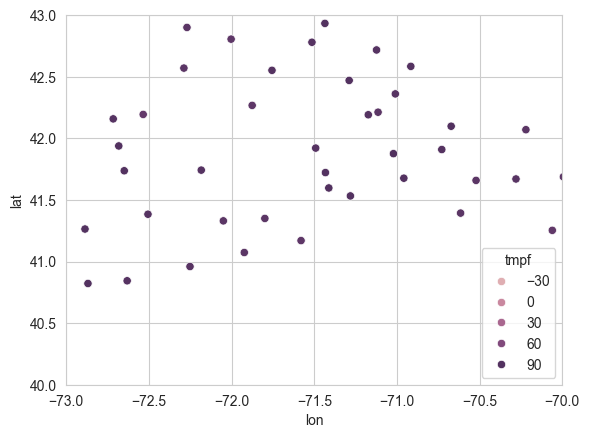

In [41]:
sns.scatterplot(x=tmp2['lon'], y=tmp2['lat'], hue = tmp2['tmpf'])
plt.xlim([-73, -70])
plt.ylim([40, 43])
plt.show() 

Here's how you can make a basemap with it.

In [42]:
!pip install geopandas

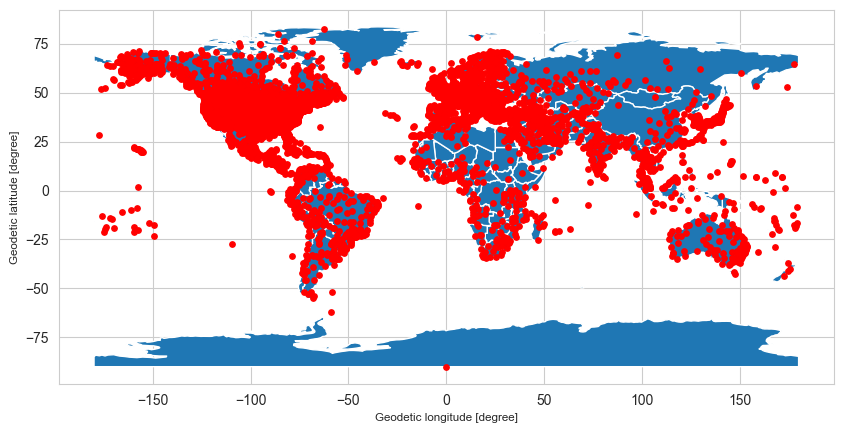

In [43]:
# https://stackoverflow.com/questions/53233228/plot-latitude-longitude-from-csv-in-python-3-6
import geopandas as gpd
from geopandas import GeoDataFrame

# a little advanced, but hack the arguments as needed
# points_from_xy turns longitude/latitude columns into map points
gdf = GeoDataFrame(tmp2, geometry=gpd.points_from_xy(tmp2['lon'], tmp2['lat']))   

# a simple world map from Natural Earth (geopandas no longer ships one built in)
world = gpd.read_file('https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip')
gdf.plot(ax=world.plot(figsize=(10, 6)), marker='o', color='red', markersize=15)
plt.show()

Try to zoom in on Connecticut - Stamford's lat/lon is 41.0534° N, 73.5387° W.

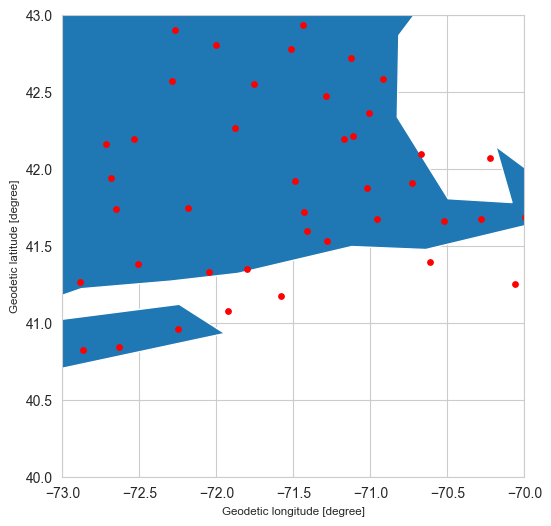

In [44]:
# https://stackoverflow.com/questions/53233228/plot-latitude-longitude-from-csv-in-python-3-6
import geopandas as gpd
from geopandas import GeoDataFrame

# a little advanced, but hack the arguments as needed
# points_from_xy turns longitude/latitude columns into map points
gdf = GeoDataFrame(tmp2, geometry=gpd.points_from_xy(tmp2['lon'], tmp2['lat']))   

# a simple world map from Natural Earth (geopandas no longer ships one built in)
world = gpd.read_file('https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip')
gdf.plot(ax=world.plot(figsize=(10, 6)), marker='o', color='red', markersize=15)
plt.xlim([-73, -70])
plt.ylim([40, 43])
plt.show()

Looks a little crude, but you can tinker on your own!

# Subset one or more airports from Connecticut
For ease, let's just subset a few airports from the Connecticut area. Bradley (BDL) near Hartford, Tweed (HVN) near New Haven, and White Plains (HPN) next to Stamford are great options for us.

In [45]:
# you'll notice I always overwrite the variable 'tmp' 
# because I'm lazy - just be careful not to overwrite something you need
# if you do, just restart and run your script or choose a different name

Here are a few ways you can select data - each has a pro or con. `.isin()` is a great option when you have a lot of unique values that you need to subset, otherwise you can subset with a logical.

Here is how to subset based on a logical with multiple conditions. Note how each condition is wrapped in `()` and we use the OR operator `|`.

In [46]:
# see how I use lower and upper case letters for my variables?
# this is just my style - you could also use underscores

# select one station
tmp = df[(df['station']=='BDL')].copy() # .copy() = its own table
tmp.shape

(1181, 32)

When it's just one station you can do a lot right from the dataframe. A lot of `matplotlib` functionality can be controlled right from the pandas dataframe itself. Less code is better and pandas is AWESOME!

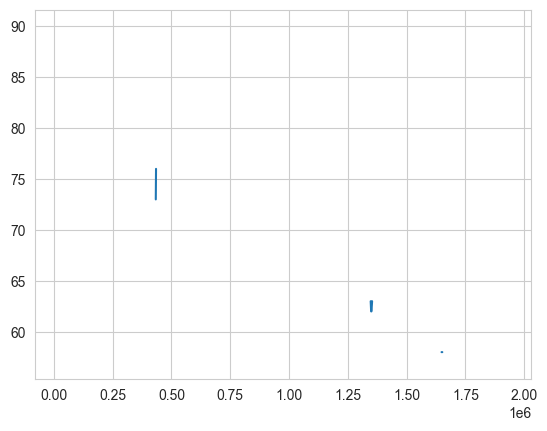

In [47]:
tmp['tmpf'].plot()
plt.show()

This plot would probably be a lot more interesting if we had a date on the X axis, which will require us to convert to a datetime object.

In [48]:
tmp['valid'] = pd.to_datetime(tmp['valid'])
tmp.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1181 entries, 75 to 1936551
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   station            1181 non-null   object        
 1   valid              1181 non-null   datetime64[ns]
 2   lon                1181 non-null   float64       
 3   lat                1181 non-null   float64       
 4   tmpf               127 non-null    float64       
 5   dwpf               127 non-null    float64       
 6   relh               127 non-null    float64       
 7   drct               1102 non-null   float64       
 8   sknt               1180 non-null   float64       
 9   p01i               168 non-null    float64       
 10  alti               1181 non-null   float64       
 11  mslp               96 non-null     float64       
 12  vsby               1181 non-null   float64       
 13  gust               51 non-null     float64       
 14  skyc1    

As you know, it's sometimes useful to set the index as the datetime column, because it allows you to take full advantage of the pandas time series functionality.
* https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html

In [49]:
tmp.set_index(tmp['valid'], inplace=True)
tmp.head() # check your work

,station,valid,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,...,wxcodes,ice_accretion_1hr,ice_accretion_3hr,ice_accretion_6hr,peak_wind_gust,peak_wind_drct,peak_wind_time,feel,metar,snowdepth
valid,,,,,,,,,,,,,,,,,,,,,
2020-08-25 00:00:00,BDL,2020-08-25 00:00:00,-72.6825,41.9381,NaN,NaN,NaN,170.0,2.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250000Z AUTO 17002KT 10SM CLR 24/20 A2989...,M
2020-08-25 00:05:00,BDL,2020-08-25 00:05:00,-72.6825,41.9381,NaN,NaN,NaN,160.0,2.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250005Z AUTO 16002KT 10SM CLR 24/20 A2989...,M
2020-08-25 00:10:00,BDL,2020-08-25 00:10:00,-72.6825,41.9381,NaN,NaN,NaN,170.0,2.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250010Z AUTO 17002KT 10SM CLR 24/20 A2989...,M
2020-08-25 00:15:00,BDL,2020-08-25 00:15:00,-72.6825,41.9381,NaN,NaN,NaN,0.0,0.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250015Z AUTO 00000KT 10SM CLR 24/21 A2989...,M
2020-08-25 00:20:00,BDL,2020-08-25 00:20:00,-72.6825,41.9381,NaN,NaN,NaN,0.0,0.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250020Z AUTO 00000KT 10SM CLR 24/21 A2989...,M


Now your code knows what to do - make a plot of temperature!

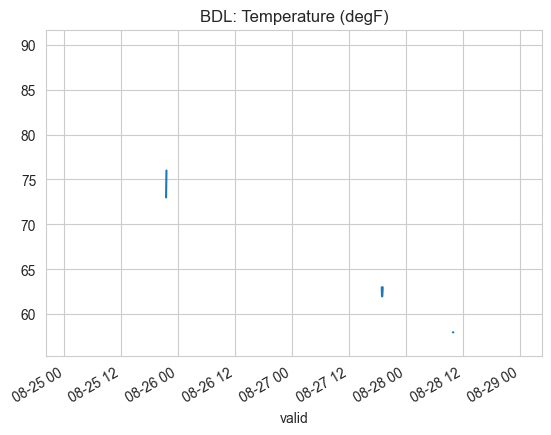

In [50]:
# notice how the plot changed with the proper axis! 
# this plot is way different than the one above
# this is due to clumpy/frequent observations
tmp['tmpf'].plot()
plt.title('BDL: Temperature (degF)')
plt.show()

## Selecting multiple stations

In [51]:
# select three stations
tmp2 = df[(df['station']=='BDL') | (df['station']=='HVN') | (df['station']=='HPN')].copy()
tmp2.shape

(3694, 32)

It would be a fruitful exercise to go from long to wide now! When you do, you may come up with a multi-index. You can read about this on your own. For now we will collapse the index so we have one set of column names.

* https://stackoverflow.com/questions/34988040/long-to-wide-data-pandas

In [52]:
# first, make sure that 'valid' is a datetime for easy analysis/resampling later on
tmp2['valid'] = pd.to_datetime(tmp2['valid'])

In [53]:
# let's make a pivot table
tmp3 = pd.pivot_table(tmp2, index='valid', columns=['station'], aggfunc='max')

# check your work
tmp3.head()

alti                 drct               dwpf          \
station               BDL    HPN    HVN    BDL    HPN    HVN  BDL HPN HVN   
valid                                                                       
2020-08-25 00:00:00  29.9  29.92  29.91  170.0    0.0  180.0  NaN NaN NaN   
2020-08-25 00:05:00  29.9  29.92  29.91  160.0    0.0  180.0  NaN NaN NaN   
2020-08-25 00:10:00  29.9  29.92  29.91  170.0  260.0  180.0  NaN NaN NaN   
2020-08-25 00:15:00  29.9  29.92  29.91    0.0  270.0  170.0  NaN NaN NaN   
2020-08-25 00:20:00  29.9  29.92  29.91    0.0  260.0  170.0  NaN NaN NaN   

                    feel  ... snowdepth tmpf          vsby              \
station              BDL  ...       HVN  BDL HPN HVN   BDL   HPN   HVN   
valid                     ...                                            
2020-08-25 00:00:00    M  ...         M  NaN NaN NaN  10.0  10.0  10.0   
2020-08-25 00:05:00    M  ...         M  NaN NaN NaN  10.0  10.0  10.0   
2020-08-25 00:10:00    M  ...         M  NaN NaN NaN  10.0  10.0  10.0   
2020-08-25 00:15:00    M  ...         M  NaN NaN NaN  10.0  10.0  10.0   
2020-08-25 00:20:00    M  ...         M  NaN NaN NaN  10.0  10.0  10.0   

                    wxcodes          
station                 BDL HPN HVN  
valid                                
2020-08-25 00:00:00       M   M   M  
2020-08-25 00:05:00       M   M   M  
2020-08-25 00:10:00       M   M   M  
2020-08-25 00:15:00       M   M   M  
2020-08-25 00:20:00       M   M   M  

[5 rows x 90 columns]

The concept of a multi-index can be annoying... we can squish it down further if we want and rename the columns.

In [54]:
#reset multicolumns
# this strips the whitespace and joins them together with a _
tmp3.columns = tmp3.columns.map('_'.join)
print(tmp3.shape)
tmp3.head() # see how these are easier to work with?


(1482, 90)


,alti_BDL,alti_HPN,alti_HVN,drct_BDL,drct_HPN,drct_HVN,dwpf_BDL,dwpf_HPN,dwpf_HVN,feel_BDL,...,snowdepth_HVN,tmpf_BDL,tmpf_HPN,tmpf_HVN,vsby_BDL,vsby_HPN,vsby_HVN,wxcodes_BDL,wxcodes_HPN,wxcodes_HVN
valid,,,,,,,,,,,,,,,,,,,,,
2020-08-25 00:00:00,29.9,29.92,29.91,170.0,0.0,180.0,NaN,NaN,NaN,M,...,M,NaN,NaN,NaN,10.0,10.0,10.0,M,M,M
2020-08-25 00:05:00,29.9,29.92,29.91,160.0,0.0,180.0,NaN,NaN,NaN,M,...,M,NaN,NaN,NaN,10.0,10.0,10.0,M,M,M
2020-08-25 00:10:00,29.9,29.92,29.91,170.0,260.0,180.0,NaN,NaN,NaN,M,...,M,NaN,NaN,NaN,10.0,10.0,10.0,M,M,M
2020-08-25 00:15:00,29.9,29.92,29.91,0.0,270.0,170.0,NaN,NaN,NaN,M,...,M,NaN,NaN,NaN,10.0,10.0,10.0,M,M,M
2020-08-25 00:20:00,29.9,29.92,29.91,0.0,260.0,170.0,NaN,NaN,NaN,M,...,M,NaN,NaN,NaN,10.0,10.0,10.0,M,M,M


Now you can resample and explore!

In [55]:
# '60min' = hourly; numeric_only=True skips text columns (you can't take the max of a sentence!)
tmp3 = tmp3.resample('60min').max(numeric_only=True)

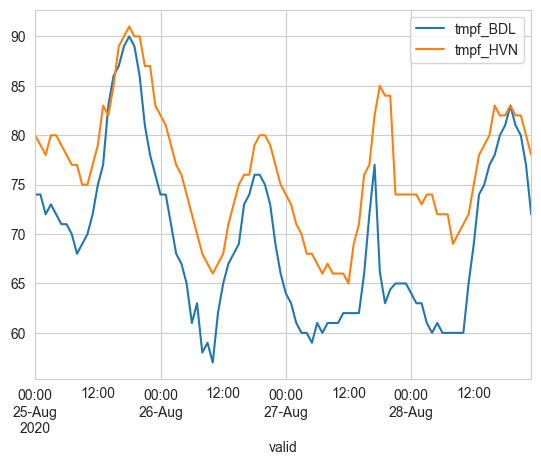

In [56]:
tmp3[['tmpf_BDL', 'tmpf_HVN']].plot()
plt.show()

See how easy it is to line up variables when they are on the same time scale! Looks like HVN was a little bit warmer than BDL. You can also customize the plot on your own.

# Join weather and energy data together
The energy data is VERY CLEAN. It is on an hourly resoultion. 

The weather data is more chaotic - you will need to resample to hourly resolution. 

Fortunately, pandas has a whole mess of tools that are useful for resampling time series data.

* https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html

In [57]:
# we can make a copy of the dataset for clearer names
weather = tmp
weather.head() # check your work

,station,valid,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,...,wxcodes,ice_accretion_1hr,ice_accretion_3hr,ice_accretion_6hr,peak_wind_gust,peak_wind_drct,peak_wind_time,feel,metar,snowdepth
valid,,,,,,,,,,,,,,,,,,,,,
2020-08-25 00:00:00,BDL,2020-08-25 00:00:00,-72.6825,41.9381,NaN,NaN,NaN,170.0,2.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250000Z AUTO 17002KT 10SM CLR 24/20 A2989...,M
2020-08-25 00:05:00,BDL,2020-08-25 00:05:00,-72.6825,41.9381,NaN,NaN,NaN,160.0,2.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250005Z AUTO 16002KT 10SM CLR 24/20 A2989...,M
2020-08-25 00:10:00,BDL,2020-08-25 00:10:00,-72.6825,41.9381,NaN,NaN,NaN,170.0,2.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250010Z AUTO 17002KT 10SM CLR 24/20 A2989...,M
2020-08-25 00:15:00,BDL,2020-08-25 00:15:00,-72.6825,41.9381,NaN,NaN,NaN,0.0,0.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250015Z AUTO 00000KT 10SM CLR 24/21 A2989...,M
2020-08-25 00:20:00,BDL,2020-08-25 00:20:00,-72.6825,41.9381,NaN,NaN,NaN,0.0,0.0,NaN,...,M,M,M,M,M,M,M,M,KBDL 250020Z AUTO 00000KT 10SM CLR 24/21 A2989...,M


In [58]:
metar = weather['metar'] # save the text column before resampling
weather = weather.resample('60min').max(numeric_only=True) # max hourly temperature
weather['metar'] = metar.resample('60min').last() # the last METAR report of each hour
weather # check your work

,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,alti,mslp,vsby,gust,metar
valid,,,,,,,,,,,,,
2020-08-25 00:00:00,-72.6825,41.9381,74.0,69.0,84.97,240.0,3.0,0.0,29.91,1012.5,10.0,NaN,KBDL 250055Z AUTO 24002KT 10SM CLR 23/21 A2990...
2020-08-25 01:00:00,-72.6825,41.9381,74.0,70.0,87.63,260.0,4.0,0.0,29.91,1012.1,10.0,NaN,KBDL 250155Z AUTO 21002KT 10SM CLR 23/21 A2988...
2020-08-25 02:00:00,-72.6825,41.9381,72.0,70.0,93.43,230.0,5.0,0.0,29.89,1011.8,10.0,NaN,KBDL 250255Z AUTO 19004KT 10SM CLR 23/21 A2987...
2020-08-25 03:00:00,-72.6825,41.9381,73.0,70.0,90.32,230.0,5.0,0.0,29.88,1011.6,10.0,NaN,KBDL 250355Z AUTO 23002KT 10SM CLR 22/21 A2987...
2020-08-25 04:00:00,-72.6825,41.9381,72.0,70.0,93.43,190.0,5.0,0.0,29.88,1011.3,10.0,NaN,KBDL 250455Z AUTO 00000KT 10SM CLR 22/21 A2987...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-08-28 19:00:00,-72.6825,41.9381,83.0,58.0,42.63,320.0,10.0,0.0,29.80,1009.0,10.0,NaN,KBDL 281955Z AUTO 31007KT 10SM SCT050 28/14 A2...
2020-08-28 20:00:00,-72.6825,41.9381,81.0,57.0,43.90,340.0,9.0,0.0,29.80,1008.9,10.0,NaN,KBDL 282055Z AUTO 33005KT 10SM CLR 27/14 A2979...
2020-08-28 21:00:00,-72.6825,41.9381,80.0,57.0,45.21,340.0,5.0,0.0,29.79,1008.5,10.0,NaN,KBDL 282155Z AUTO 33002KT 10SM CLR 27/14 A2978...


Now everything is at hourly resolution - we are ready for a join!
* https://www.statology.org/pandas-merge-on-index/

In [59]:
# we will do the join on the index!
# if you are doing it by a column, this will be different syntax
df = weather.join(energy) # weather = left, energy = right
df # check your work!

,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,alti,mslp,vsby,gust,metar,H,Date,HE,MWh
valid,,,,,,,,,,,,,,,,,
2020-08-25 00:00:00,-72.6825,41.9381,74.0,69.0,84.97,240.0,3.0,0.0,29.91,1012.5,10.0,NaN,KBDL 250055Z AUTO 24002KT 10SM CLR 23/21 A2990...,D,2020-08-25 00:00:00,0,14986.78
2020-08-25 01:00:00,-72.6825,41.9381,74.0,70.0,87.63,260.0,4.0,0.0,29.91,1012.1,10.0,NaN,KBDL 250155Z AUTO 21002KT 10SM CLR 23/21 A2988...,D,2020-08-25 01:00:00,1,14433.29
2020-08-25 02:00:00,-72.6825,41.9381,72.0,70.0,93.43,230.0,5.0,0.0,29.89,1011.8,10.0,NaN,KBDL 250255Z AUTO 19004KT 10SM CLR 23/21 A2987...,D,2020-08-25 02:00:00,2,14152.24
2020-08-25 03:00:00,-72.6825,41.9381,73.0,70.0,90.32,230.0,5.0,0.0,29.88,1011.6,10.0,NaN,KBDL 250355Z AUTO 23002KT 10SM CLR 22/21 A2987...,D,2020-08-25 03:00:00,3,13846.08
2020-08-25 04:00:00,-72.6825,41.9381,72.0,70.0,93.43,190.0,5.0,0.0,29.88,1011.3,10.0,NaN,KBDL 250455Z AUTO 00000KT 10SM CLR 22/21 A2987...,D,2020-08-25 04:00:00,4,13872.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-08-28 19:00:00,-72.6825,41.9381,83.0,58.0,42.63,320.0,10.0,0.0,29.80,1009.0,10.0,NaN,KBDL 281955Z AUTO 31007KT 10SM SCT050 28/14 A2...,D,2020-08-28 19:00:00,19,16324.76
2020-08-28 20:00:00,-72.6825,41.9381,81.0,57.0,43.90,340.0,9.0,0.0,29.80,1008.9,10.0,NaN,KBDL 282055Z AUTO 33005KT 10SM CLR 27/14 A2979...,D,2020-08-28 20:00:00,20,15897.55
2020-08-28 21:00:00,-72.6825,41.9381,80.0,57.0,45.21,340.0,5.0,0.0,29.79,1008.5,10.0,NaN,KBDL 282155Z AUTO 33002KT 10SM CLR 27/14 A2978...,D,2020-08-28 21:00:00,21,14995.91


In [60]:
df.shape

(96, 17)

# Time to Analyze!
Now there are infinite ways that one can tease out the relationship between energy and weather. 

You should anticipate how many rows and columns there should be - and get ready to clean up even further to make your life easier.

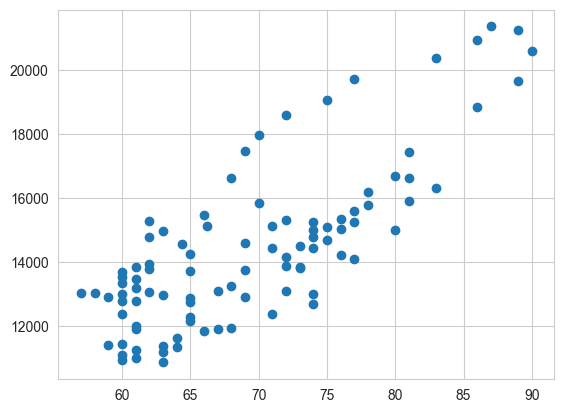

In [61]:
plt.scatter(x=df['tmpf'], y= df['MWh'])
plt.show()

On your own: Add a linear trend line and the equation of the line to this plot (like Excel.) You can also try to add a polynomial. 

* https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html
* https://stackoverflow.com/questions/49460596/add-trendline-with-equation-in-2d-array

We can save a copy of the dataset and keep working on it later.

In [62]:
df.to_csv('cleanweather_energy.csv') # this will download to the runtime on the left

Let's think about all the things we can do with this dataset... you likely don't know how to do all of these, so search for the answer when you are stuck! 

1. Day of the week (Monday, Tuesday, Wednesday) and color code the scatterplot of tmpf vs. MWh by day of week
2. How many hours were above 70 degF in your dataset?
3. Calculate the mean or max consecutive values above a threshold (like 70 degF vs. 80 degF)
4. Shift the weather or energy variables by 1, 6 or 12 time steps and make scatterplots.
5. What is the correlation between previous one hour and current hour? Six hours and current hour? 12 hours and current hour? 24 hours and current hour? Which of these do you think would be a fair baseline model?
6. Calculate a 2, 3, 6, 12 hr rolling means as new columns in your df for both weather and energy - what do the missing values look like in your df after making these features (and think about WHY you have missing values)
7. What is the greatest hourly change? 6 hourly change? You can think of this as a slope or difference between two rows.
8. What is the greatest hourly percentage change for temperature or energy? Create a histogram of this variable.
9. Identify all of the local minima and maxima in the temperature and energy data. Plot them as points on the time series plot.
10. Return the time that temperature climbs above 70 degF each day (if at all).




In [63]:
# anyone else have something they want to try?

# Text Analytics: Working with METAR

The METAR data is quite interesting! It's the way pilots talk to teach other about the weather. Let's look at one.

* https://en.wikipedia.org/wiki/METAR#METAR_conventions

In [64]:
# first METAR
df['metar'].iloc[0]

'KBDL 250055Z AUTO 24002KT 10SM CLR 23/21 A2990 RMK T02300210 MADISHF'

Let's count the number of words in each cell.

In [65]:
# here is a nice table (just printed out, not saved anywhere)
df['metar'].str.count(r'\w+')

valid
2020-08-25 00:00:00    12
2020-08-25 01:00:00    12
2020-08-25 02:00:00    12
2020-08-25 03:00:00    12
2020-08-25 04:00:00    12
                       ..
2020-08-28 19:00:00    12
2020-08-28 20:00:00    12
2020-08-28 21:00:00    12
2020-08-28 22:00:00    12
2020-08-28 23:00:00    12
Freq: 60min, Name: metar, Length: 96, dtype: int64

In [66]:
# at first look it looks like 12 in each one... consistent!
df['metar'].str.count(r'\w+').describe()

count    96.000000
mean     13.416667
std       3.097254
min      12.000000
25%      12.000000
50%      12.000000
75%      13.250000
max      33.000000
Name: metar, dtype: float64

Looks there are some that are 12, but a few that are quite long (even if rare!) 

In [67]:
df['metar'].str.count(r'\w+').value_counts()

metar
12    66
13     6
14     5
15     4
18     3
17     3
16     3
20     2
19     2
24     1
33     1
Name: count, dtype: int64

WHOA! So there are some random ones that are quite long... why don't we save the length as a field then subset the long records to see what they look like? 

In [68]:
# make a new column with the length of the METAR
df['lenmetar'] = df['metar'].str.count(r'\w+')
df

,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,alti,mslp,vsby,gust,metar,H,Date,HE,MWh,lenmetar
valid,,,,,,,,,,,,,,,,,,
2020-08-25 00:00:00,-72.6825,41.9381,74.0,69.0,84.97,240.0,3.0,0.0,29.91,1012.5,10.0,NaN,KBDL 250055Z AUTO 24002KT 10SM CLR 23/21 A2990...,D,2020-08-25 00:00:00,0,14986.78,12
2020-08-25 01:00:00,-72.6825,41.9381,74.0,70.0,87.63,260.0,4.0,0.0,29.91,1012.1,10.0,NaN,KBDL 250155Z AUTO 21002KT 10SM CLR 23/21 A2988...,D,2020-08-25 01:00:00,1,14433.29,12
2020-08-25 02:00:00,-72.6825,41.9381,72.0,70.0,93.43,230.0,5.0,0.0,29.89,1011.8,10.0,NaN,KBDL 250255Z AUTO 19004KT 10SM CLR 23/21 A2987...,D,2020-08-25 02:00:00,2,14152.24,12
2020-08-25 03:00:00,-72.6825,41.9381,73.0,70.0,90.32,230.0,5.0,0.0,29.88,1011.6,10.0,NaN,KBDL 250355Z AUTO 23002KT 10SM CLR 22/21 A2987...,D,2020-08-25 03:00:00,3,13846.08,12
2020-08-25 04:00:00,-72.6825,41.9381,72.0,70.0,93.43,190.0,5.0,0.0,29.88,1011.3,10.0,NaN,KBDL 250455Z AUTO 00000KT 10SM CLR 22/21 A2987...,D,2020-08-25 04:00:00,4,13872.55,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-08-28 19:00:00,-72.6825,41.9381,83.0,58.0,42.63,320.0,10.0,0.0,29.80,1009.0,10.0,NaN,KBDL 281955Z AUTO 31007KT 10SM SCT050 28/14 A2...,D,2020-08-28 19:00:00,19,16324.76,12
2020-08-28 20:00:00,-72.6825,41.9381,81.0,57.0,43.90,340.0,9.0,0.0,29.80,1008.9,10.0,NaN,KBDL 282055Z AUTO 33005KT 10SM CLR 27/14 A2979...,D,2020-08-28 20:00:00,20,15897.55,12
2020-08-28 21:00:00,-72.6825,41.9381,80.0,57.0,45.21,340.0,5.0,0.0,29.79,1008.5,10.0,NaN,KBDL 282155Z AUTO 33002KT 10SM CLR 27/14 A2978...,D,2020-08-28 21:00:00,21,14995.91,12


In [69]:
# subset to examine
tmp = df.loc[df['lenmetar']>12]
tmp

,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,alti,mslp,vsby,gust,metar,H,Date,HE,MWh,lenmetar
valid,,,,,,,,,,,,,,,,,,
2020-08-25 05:00:00,-72.6825,41.9381,71.0,69.0,93.40,190.0,4.0,0.0000,29.87,1010.8,10.0,NaN,KBDL 250551Z 19004KT 8SM FEW180 22/21 A2985 RM...,D,2020-08-25 05:00:00,5,14420.10,15
2020-08-25 10:00:00,-72.6825,41.9381,70.0,67.0,89.90,230.0,4.0,0.0000,29.82,1009.2,10.0,NaN,KBDL 251051Z 00000KT 10SM FEW075 SCT150 BKN250...,D,2020-08-25 10:00:00,10,17972.45,14
2020-08-25 11:00:00,-72.6825,41.9381,72.0,67.0,83.99,220.0,5.0,0.0000,29.81,1008.9,10.0,NaN,KBDL 251151Z 19004KT 10SM FEW080 SCT120 BKN250...,D,2020-08-25 11:00:00,11,18582.74,18
2020-08-25 12:00:00,-72.6825,41.9381,75.0,68.0,78.86,220.0,5.0,0.0000,29.80,1008.5,10.0,NaN,KBDL 251251Z 21005KT 10SM FEW050 SCT120 BKN250...,D,2020-08-25 12:00:00,12,19047.27,17
2020-08-25 15:00:00,-72.6825,41.9381,86.0,59.0,40.14,320.0,14.0,0.0000,29.76,1007.2,10.0,19.0,KBDL 251551Z 31009KT 280V350 10SM FEW045 FEW15...,D,2020-08-25 15:00:00,15,20941.57,16
2020-08-25 21:00:00,-72.6825,41.9381,81.0,69.0,76.53,330.0,30.0,0.1100,29.70,1005.4,10.0,42.0,KBDL 252155Z AUTO 30010KT 10SM SCT095 26/21 A2...,D,2020-08-25 21:00:00,21,17434.29,17
2020-08-25 22:00:00,-72.6825,41.9381,78.0,66.0,66.39,300.0,13.0,0.0000,29.70,1005.6,10.0,NaN,KBDL 252255Z AUTO 29009KT 10SM FEW050 FEW070 2...,D,2020-08-25 22:00:00,22,15777.38,13
2020-08-25 23:00:00,-72.6825,41.9381,76.0,59.0,55.80,310.0,13.0,0.0000,29.72,1006.4,10.0,NaN,KBDL 252351Z 31009KT 10SM FEW055 FEW075 FEW100...,D,2020-08-25 23:00:00,23,14207.33,24
2020-08-26 12:00:00,-72.6825,41.9381,65.0,46.0,50.32,360.0,10.0,0.0000,29.93,1013.0,10.0,NaN,KBDL 261251Z 36009KT 10SM FEW040 BKN250 18/08 ...,D,2020-08-26 12:00:00,12,12875.84,13


Since there aren't that many, maybe we can look at the METARs for trends. 

In [70]:
# it can be tough for pandas to print the entire series
tmp['metar'].unique()

array(['KBDL 250551Z 19004KT 8SM FEW180 22/21 A2985 RMK AO2 SLP108 T02170206 10250 20206 58010',
       'KBDL 251051Z 00000KT 10SM FEW075 SCT150 BKN250 21/19 A2981 RMK AO2 SLP092 T02110194',
       'KBDL 251151Z 19004KT 10SM FEW080 SCT120 BKN250 22/19 A2980 RMK AO2 SLP089 70018 T02220194 10222 20194 58006',
       'KBDL 251251Z 21005KT 10SM FEW050 SCT120 BKN250 24/20 A2979 RMK AO2 LTG DSNT SW SLP085 T02390200',
       'KBDL 251551Z 31009KT 280V350 10SM FEW045 FEW150 SCT200 BKN250 30/15 A2975 RMK AO2 SLP072 T03000150',
       'KBDL 252155Z AUTO 30010KT 10SM SCT095 26/21 A2969 RMK T02600210  LTG DSNT E AND SE! MADISHF',
       'KBDL 252255Z AUTO 29009KT 10SM FEW050 FEW070 25/19 A2970 RMK T02500190 MADISHF',
       'KBDL 252351Z 31009KT 10SM FEW055 FEW075 FEW100 SCT250 24/15 A2972 RMK AO2 SLP064 CB DSNT SE MOV SE 60011 T02440150 10322 20228 53015',
       'KBDL 261251Z 36009KT 10SM FEW040 BKN250 18/08 A2992 RMK AO2 SLP130 T01830078',
       'KBDL 270551Z 00000KT 10SM FEW110 SCT150 SCT230 

Despite our best efforts, it probably would be tough to line up all of these columns as new variables - we would hope for the 12 standard variables listed on the Wikipedia page. So, for METARs where length is equal to 12, let's parse and make 12 new variables which we can clean up later!

In [71]:
# it's not pretty, but let's delete rows that have more than 12 metars - too complicated for us right now
tmp = df[df['lenmetar']==12].copy()
tmp.shape

(66, 18)

In [72]:
# we lost a few records - this is OK for now - just a demonstration
df.shape

(96, 18)

Now let's create 12 new variables in `tmp` that we hope line up with the METAR data.
* https://stackoverflow.com/questions/14745022/how-to-split-a-dataframe-string-column-into-two-columns

In [73]:
# i hacked the code to split by a delimeter
tmp['metar'].str.split(' ', expand=True)

,0,1,2,3,4,5,6,7,8,9,10
valid,,,,,,,,,,,
2020-08-25 00:00:00,KBDL,250055Z,AUTO,24002KT,10SM,CLR,23/21,A2990,RMK,T02300210,MADISHF
2020-08-25 01:00:00,KBDL,250155Z,AUTO,21002KT,10SM,CLR,23/21,A2988,RMK,T02300210,MADISHF
2020-08-25 02:00:00,KBDL,250255Z,AUTO,19004KT,10SM,CLR,23/21,A2987,RMK,T02300210,MADISHF
2020-08-25 03:00:00,KBDL,250355Z,AUTO,23002KT,10SM,CLR,22/21,A2987,RMK,T02200210,MADISHF
2020-08-25 04:00:00,KBDL,250455Z,AUTO,00000KT,10SM,CLR,22/21,A2987,RMK,T02200210,MADISHF
...,...,...,...,...,...,...,...,...,...,...,...
2020-08-28 19:00:00,KBDL,281955Z,AUTO,31007KT,10SM,SCT050,28/14,A2979,RMK,T02800140,MADISHF
2020-08-28 20:00:00,KBDL,282055Z,AUTO,33005KT,10SM,CLR,27/14,A2979,RMK,T02700140,MADISHF
2020-08-28 21:00:00,KBDL,282155Z,AUTO,33002KT,10SM,CLR,27/14,A2978,RMK,T02700140,MADISHF


Now let's join it back to the original dataset...

In [74]:
# make the new columns (for now, with boring names)
tmp[['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11']] = tmp['metar'].str.split(' ', expand=True)
tmp.head() # check your work!

,lon,lat,tmpf,dwpf,relh,drct,sknt,p01i,alti,mslp,...,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11
valid,,,,,,,,,,,,,,,,,,,,,
2020-08-25 00:00:00,-72.6825,41.9381,74.0,69.0,84.97,240.0,3.0,0.0,29.91,1012.5,...,250055Z,AUTO,24002KT,10SM,CLR,23/21,A2990,RMK,T02300210,MADISHF
2020-08-25 01:00:00,-72.6825,41.9381,74.0,70.0,87.63,260.0,4.0,0.0,29.91,1012.1,...,250155Z,AUTO,21002KT,10SM,CLR,23/21,A2988,RMK,T02300210,MADISHF
2020-08-25 02:00:00,-72.6825,41.9381,72.0,70.0,93.43,230.0,5.0,0.0,29.89,1011.8,...,250255Z,AUTO,19004KT,10SM,CLR,23/21,A2987,RMK,T02300210,MADISHF
2020-08-25 03:00:00,-72.6825,41.9381,73.0,70.0,90.32,230.0,5.0,0.0,29.88,1011.6,...,250355Z,AUTO,23002KT,10SM,CLR,22/21,A2987,RMK,T02200210,MADISHF
2020-08-25 04:00:00,-72.6825,41.9381,72.0,70.0,93.43,190.0,5.0,0.0,29.88,1011.3,...,250455Z,AUTO,00000KT,10SM,CLR,22/21,A2987,RMK,T02200210,MADISHF


Can you read Wikipedia and figure out how to decipher the METAR into your other weather variables? This is a great exercise!

On your own, you can make all text upper case or lower case, or select values from METAR based on a condition.